# Spellchecker quest

Хтось наробив помилок у віршах Тараса Шевченка. Ваша задача -- виправити ці помилки і прочитати приховане повідомлення.

## Задача

Ви отримаєте тренувальні та тестувальні дані.

Тренувальні дані знаходяться в полі `lab.train_text`. Це звичайний нерозмічений текст. На ньому необхідно натренувати мовну модель. Підійде будь-яка: n-грамна, feed-forward нейронну модель або їх ансамбль. Токенізацію раджу робити по літерах або BPE.

Тестувальні дані знаходиться в полі `lab.test_items`. Приклад одного елемента:

```json
{
  "text": "Співали б прозу, та по ножах,",
  "error_start": 23,
  "error_end": 28,
  "error": "ножах",
  "corrections": [
    "ногах",
    "йотах",
    "єнотах",
    "ножах",
    "нотах"
  ]
}
```

`error_start` та `error_end` вказують на місцезнаходження помилки в тексті (в символах). У цьому прикладі помилкою є `text[23:28]`, тобто слово "ножах".

`corrections` -- це список можливих виправлень.

Ваша задача -- натренувати мовну модель та за її допомогою обрати правильне виправлення серед запропонованих.


## Приховане повідомлення

Один приклад в `lab.test_items` дає можливість прочитати одну літеру прихованого повідомлення. Для цього знайдіть різницю між літерами слова з помилкою (`error`) та обраним моделлю виправленням. Надрукуйте цю літеру. Якщо слово з помилкою насправді правильне, а таке теж буває, надрукуйте пробіл. Приклади:

```
Error               Correction     Надрукувати
-------------------------------------------
привіт               приліт        л
пні                  поні          о
баллет               балет         л
привіт               привіт        [пробіл]
```

Приховане повідомлення, яке ви побачите в результаті -- це рядок з віршу одного з українських авторів.

Відповідь на квест -- ім'я автора/ки у форматі "Ім'я Прізвище".

Полетіли! 🚀

In [2]:
!pip install --quiet --upgrade https://static.lp-nlp.com/pypi/lpnlp-2026.10.1-py3-none-any.whl

In [3]:
import lpnlp

lab = lpnlp.start(
    email="daniil.shevchenko.shi.2023@lpnu.ua",                   # <----------- Заповніть це поле
    lab="quest_spellchecker"
    )

Удачі!


In [4]:
import math
import collections
from typing import List, Tuple, Dict
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torch.nn.functional as F
import io
import re
import copy
from contextlib import redirect_stdout
import math
import collections
from typing import List, Tuple

In [ ]:
# Якщо вам потрібні тренувальні дані у вигляді файлу на вашому комп'ютері,
# розкоментуйте цей код:

# with open("train.txt", "wt") as f:
#     f.write(lab.train_text)

# from google.colab import files
# files.download("train.txt")

In [5]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Мовна модель

Натренуйте свою мовну модель тут

In [6]:
print(lab.train_text[:330])

ПРИЧИННА

Реве та стогне Дніпр широкий,
Сердитий вітер завива,
Додолу верби гне високі,
Горами хвилю підійма.
І блідий місяць на ту пору
Із хмари де-де виглядав,
Неначе човен в синім морі,
То виринав, то потопав.
Ще треті півні не співали,
Ніхто нігде не гомонів,
Сичі в гаю перекликались,
Та ясен раз у раз скрипів.
В таку добу п


In [7]:
train_text = lab.train_text


BOS_CHAR = "\0"
UNK_TOKEN = "<unk>"
special_tokens = [BOS_CHAR, UNK_TOKEN] ##спеціальні токени
unique_chars = sorted(list(set(train_text))) ##вибір унікальних токенів(символів) з усього тексту "Кобзаря"
vocab_chars = special_tokens + [c for c in unique_chars if c not in special_tokens] ##повний словник

char_to_id_dictionary = {char : id for id, char in enumerate(vocab_chars)}
id_to_char_dictionary = {id : char for id, char in enumerate(vocab_chars)}
print(f"Char to Id: {char_to_id_dictionary}")
print(f"Id to char: {id_to_char_dictionary}")

VOCAB_SIZE = len(char_to_id_dictionary)
print(f"Vocabulary size: {VOCAB_SIZE}")

UNK_ID = char_to_id_dictionary[UNK_TOKEN]
BOS_ID = char_to_id_dictionary[BOS_CHAR]
PAD_ID = char_to_id_dictionary[BOS_CHAR]
print("Begin of Sequence:", BOS_ID)
print("Unknown:", UNK_ID)

Char to Id: {'\x00': 0, '<unk>': 1, '\n': 2, ' ': 3, '!': 4, '"': 5, "'": 6, '(': 7, ')': 8, '*': 9, ',': 10, '-': 11, '.': 12, '0': 13, '1': 14, '2': 15, '3': 16, '4': 17, '5': 18, '6': 19, '7': 20, '8': 21, '9': 22, ':': 23, ';': 24, '?': 25, 'A': 26, 'B': 27, 'D': 28, 'I': 29, 'N': 30, 'T': 31, 'U': 32, 'V': 33, 'X': 34, '[': 35, ']': 36, 'd': 37, 'e': 38, 'm': 39, 'u': 40, '«': 41, '»': 42, 'Є': 43, 'І': 44, 'Ї': 45, 'А': 46, 'Б': 47, 'В': 48, 'Г': 49, 'Д': 50, 'Е': 51, 'Ж': 52, 'З': 53, 'И': 54, 'Й': 55, 'К': 56, 'Л': 57, 'М': 58, 'Н': 59, 'О': 60, 'П': 61, 'Р': 62, 'С': 63, 'Т': 64, 'У': 65, 'Ф': 66, 'Х': 67, 'Ц': 68, 'Ч': 69, 'Ш': 70, 'Щ': 71, 'Ы': 72, 'Ь': 73, 'Э': 74, 'Ю': 75, 'Я': 76, 'а': 77, 'б': 78, 'в': 79, 'г': 80, 'д': 81, 'е': 82, 'ж': 83, 'з': 84, 'и': 85, 'й': 86, 'к': 87, 'л': 88, 'м': 89, 'н': 90, 'о': 91, 'п': 92, 'р': 93, 'с': 94, 'т': 95, 'у': 96, 'ф': 97, 'х': 98, 'ц': 99, 'ч': 100, 'ш': 101, 'щ': 102, 'ъ': 103, 'ы': 104, 'ь': 105, 'э': 106, 'ю': 107, 'я': 108,

In [8]:
class NGramStatisticalModel:
  def __init__(self, n, vocab, alpha):
    self.n = n
    self.alpha = alpha
    self.counts = collections.defaultdict(collections.Counter) #словник рахує, скільки разів певний символ (target) зустрівся після (n-1) конкретних попередніх (context)
    self.context_totals = collections.defaultdict(int) #словник рахує, скільки разів такий контекст з (n-1) символів зустрічався
    self.vocab = vocab
    self.vocab_size = len(vocab)

  def train(self, text):
    text_with_padding = (BOS_CHAR * (self.n - 1)) + text
    for char_index in range(self.n - 1, len(text_with_padding)):
        context = text_with_padding[char_index - (self.n - 1) : char_index]
        target = text_with_padding[char_index]
        self.counts[context][target] += 1
        self.context_totals[context] += 1

  def get_log_probability(self, char, context):
    char_after_context_count = self.counts[context][char]
    total_context_count = self.context_totals[context]
    probability = (char_after_context_count + self.alpha) / (total_context_count + self.alpha * self.vocab_size) #обрахунок ймовірності зі згладжуванням Ліндстоуна
    return math.log(probability)

  def get_text_average_negative_log_likelihood(self, text):
    text_with_padding =  (BOS_CHAR * (self.n - 1)) + text
    total_negative_log_likelihood = 0.0
    predicted_chars_amount = 0
    for char_index in range(self.n - 1, len(text_with_padding)):
      context = text_with_padding[char_index - (self.n - 1) : char_index]
      target = text_with_padding[char_index]
      target = target if target in self.vocab else UNK_TOKEN
      log_probability = self.get_log_probability(target, context)

      total_negative_log_likelihood += (-log_probability)
      predicted_chars_amount += 1

    return total_negative_log_likelihood / predicted_chars_amount if predicted_chars_amount > 0 else float("inf")

In [9]:
n_gram_model = NGramStatisticalModel(n = 5, alpha = 0.1, vocab = char_to_id_dictionary)
n_gram_model.train(train_text)

In [10]:
vocab = vocab_chars
model = n_gram_model

# Читаємо між рядків

In [11]:
# Допоміжна функція:
def get_letter(error: str, correction: str) -> str:
    """Повертає літеру повідомлення або пробіл для незміненого слова."""
    error = error.lower()
    correction = correction.lower()

    if error == correction:
        return " "

    added = collections.Counter(correction) - collections.Counter(error)
    removed = collections.Counter(error) - collections.Counter(correction)
    difference = added or removed

    if sum(difference.values()) != 1:
        raise ValueError(
            f"Очікувалася різниця в одну літеру: {error!r} → {correction!r}"
        )

    return next(iter(difference))

assert get_letter("привіт", "приліт") == "л"
assert get_letter("пні", "поні") == "о"
assert get_letter("баллет", "балет") == "л"
assert get_letter("Привіт", "привіт") == " "


def score_text(text: str, model, vocab) -> float:
    """
    Повертає perplexity або negative log-likelihood для тексту
    (менше -- краще).
    """
    return model.get_text_average_negative_log_likelihood(text)


def solve(model, vocab, test_items) -> Tuple[List[str], str]:
    """Повертає список виправлених слів для кожного з текстів в test_items та
    секретне повідомлення.
    """

    choices = []
    secret = []

    for item in test_items:
        scores = []
        error = item['error']
        for corr in item['corrections']:
            try:
                get_letter(error, corr)
            except ValueError:
                scores.append(float("inf"))
                continue

            # Підставляємо слово-кандидат в текст
            text = item['text'][:item['error_start']] + corr + item['text'][item['error_end']:]

            # Рахуємо score тексту
            score = score_text(text, model, vocab)
            scores.append(score)

            # print(f'{score:.4f} {text}')

        # Сортуємо кандидатів на виправлення за score
        result = sorted(zip(scores, item['corrections']), key=lambda x: x[0])

        # Обираємо найкращу заміну
        best = result[0]
        best_word = best[1]
        choices.append(best_word)

        # Знаходимо чергову літеру повідомлення
        error = item['error']
        letter = get_letter(error, best_word)
        secret.append(letter)

    secret_message = ''.join(secret)

    return choices, secret_message

choices, secret_message = solve(model, vocab, lab.test_items)

lab.evaluate_accuracy(choices)
print("SECRET MESSAGE: ", secret_message)

Відповідь правильна ✅
accuracy = 0.81. Непогано! Спробуй розгадай приховане повідомлення
SECRET MESSAGE:  дливик ибоспливи  ось лвої остр ви ось твоя трапашось мвоя стернова пвавить тшійємаршрут шин тобі парашут па е тебедв  либині п и своєму стерніст лиу нле і зірк  падаю ьєв гирло рік лто і т ояинтернова промовлиєпсл в  іецось кмоя  ниюце  рибильські човни це  н ч це  тек я цевн мертьпп вно мс  життя   е т ш  й с іхюйого ст  еонишвсіхнй гои истачить в ім ш сім коханн м моям  ому лети б бо л  и  я зна  всі мост  знаю всійп яки роблю все навпакиплрше тв я слов  лише таємнибі й д в  лишелсдовідь і піст в гдвому з портових міст кохай рибо кохай   й безнадійко хай хайтбез жодн х надій  радій  ибошрадію любовчварта всього гварта болюствог  варта т оїмурозлук єарта відрази   м квпсяч г  вло ое иття шаленств ютатмилосердьпвадта н в тьтж ття не каж чи юже про смерть


In [ ]:
lab.answer("Сергій Жадан")   # Замініть на ім'я автора/ки розшифрованих рядків

Відповідь правильна ✅
Правильно! 🚀 Заповни тепер цю форму, будь ласка: https://tally.so/r/wkl0zZ


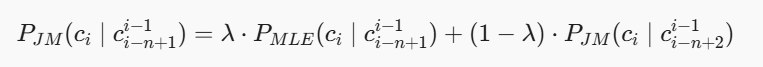

In [12]:
class InterpolatedNGram: ##Інтерполяція за принципом Єлінека-Мерсера
    def __init__(self, max_n: int = 7, lambda_val: float = 0.65):
        self.max_n = max_n
        self.lambda_val = lambda_val
        self.counts = [collections.defaultdict(collections.Counter) for _ in range(max_n + 1)]
        self.context_totals = [collections.defaultdict(int) for _ in range(max_n + 1)]
        self.vocab_size = VOCAB_SIZE
        self.total_chars = 0

    def train(self, text: str):
        self.total_chars = len(text)
        for ch in text:
            self.counts[1][""][ch] += 1
        self.context_totals[1][""] = len(text)

        text_with_padding = (BOS_CHAR * (self.max_n - 1)) + text
        for n in range(2, self.max_n + 1):
            shift = n - 1
            for char_index in range(shift, len(text_with_padding)):
                context = text_with_padding[char_index - shift : char_index]
                target = text_with_padding[char_index]
                self.counts[n][context][target] += 1
                self.context_totals[n][context] += 1

    def get_char_probability(self, char: str, context: str) -> float: #обрахунок ймовірності символа з інтерполяцією Єлінека-Мерсера
        cnt1 = self.counts[1][""].get(char, 0)
        prob = (cnt1 + 0.05) / (self.total_chars + 0.05 * self.vocab_size) #тут згладжування Ліндстона з коефіцієнтом 0.05

        for n in range(2, min(len(context) + 1, self.max_n) + 1):
            limited_context = context[-(n - 1):]
            total_limited_context_amount = self.context_totals[n].get(limited_context, 0)
            if total_limited_context_amount > 0:
                mle = self.counts[n][limited_context].get(char, 0) / total_limited_context_amount
                prob = self.lambda_val * mle + (1.0 - self.lambda_val) * prob
            else:
                prob = (1.0 - self.lambda_val) * prob

        return max(prob, 1e-12)

    def get_text_average_negative_log_likelihood_between_positions(self, new_text, eval_start, eval_end):
          nll_ngram = 0.0
          eval_len = eval_end - eval_start
          for char_index in range(eval_start, eval_end):
              context = new_text[max(0, char_index - (self.max_n - 1)) : char_index]
              target = new_text[char_index]
              prob = self.get_char_probability(target, context)
              nll_ngram -= math.log(prob)
          avg_nll_ngram = nll_ngram / eval_len
          return avg_nll_ngram



print("Навчання 7-грамної моделі з інтерполяцією...")
modified_ngram_model = InterpolatedNGram(max_n=7, lambda_val=0.65)
modified_ngram_model.train(train_text)


Навчання 7-грамної моделі з інтерполяцією...


In [13]:
class BengioCharLM(nn.Module):
    def __init__(self, vocab_size: int = VOCAB_SIZE, embed_dim: int = 48,
                 context_size: int = 10, hidden_dim: int = 256):
        super().__init__()
        self.context_size = context_size
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.net = nn.Sequential(
            nn.Linear(context_size * embed_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.GELU(),
            nn.Linear(hidden_dim // 2, vocab_size)
        )
        #будуть вертатись сирі логіти, які далі будуть використовуватись через nn.CrossEntropyLoss

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        emb = self.embedding(x)
        flat = emb.view(x.size(0), -1)
        return self.net(flat)

In [14]:
def score_candidate_ensemble(
    original_text: str,
    start: int,
    end: int,
    corrected_word: str,
    nn_model,
    ngram_model,
    weight_ngram: float = 0.45,
    weight_nn: float = 0.55,
) -> float:
    new_text = original_text[:start] + corrected_word + original_text[end:] #текст з вставленим (замість помилки) виправленим словом
    new_end = start + len(corrected_word) #позиція, де закінчується підставлене слово в новому тексті

    eval_start = start
    eval_end = min(len(new_text), new_end + 10)
    eval_len = eval_end - eval_start
    if eval_len <= 0:
        return float("inf")

    # Оцінювання N-грамою
    avg_nll_ngram = ngram_model.get_text_average_negative_log_likelihood_between_positions(new_text, eval_start, eval_end)
    # Оцінювання нейромережею
    encoded = [char_to_id_dictionary.get(c, UNK_ID) for c in new_text]
    padded_encoded = [PAD_ID] * CONTEXT_SIZE + encoded

    windows = []
    targets = []
    for char_index in range(eval_start, eval_end):
        target_position = CONTEXT_SIZE + char_index
        windows.append(padded_encoded[target_position - CONTEXT_SIZE : target_position])
        targets.append(padded_encoded[target_position])

    x_tensor = torch.tensor(windows, dtype=torch.long, device=DEVICE)
    y_tensor = torch.tensor(targets, dtype=torch.long, device=DEVICE)

    with torch.no_grad():
        logits = nn_model(x_tensor)
        avg_nll_nn = F.cross_entropy(logits, y_tensor, reduction="mean").item() #автоматично виконує рохзрахунок середнього Negative Log Likelihood

    return weight_ngram * avg_nll_ngram + weight_nn * avg_nll_nn

In [15]:
def run_evaluation(test_items, modified_gram_model, nn_model) -> Tuple[float, List[str], str]:
    nn_model.eval()
    choices = []
    secret = []

    for item in test_items:
        error = item["error"]
        start = item["error_start"]
        end = item["error_end"]
        scores = []

        for corr in item["corrections"]:
            try:
                get_letter(error, corr)
            except ValueError:
                scores.append(float("inf"))
                continue

            s = score_candidate_ensemble(item["text"], start, end, corr, nn_model, modified_ngram_model)
            scores.append(s)

        best_word = sorted(zip(scores, item["corrections"]), key=lambda x: x[0])[0][1]
        choices.append(best_word)
        secret.append(get_letter(error, best_word))

    secret_message = "".join(secret)

    output_buffer = io.StringIO()
    with redirect_stdout(output_buffer):
        lab.evaluate_accuracy(choices)
    eval_text = output_buffer.getvalue()

    print(eval_text.strip())

    match = re.search(r"accuracy\s*=\s*(\d+\.\d+)", eval_text)
    acc_val = float(match.group(1)) if match else 0.0

    return acc_val, choices, secret_message

In [16]:
CONTEXT_SIZE = 10
encoded_corpus = [char_to_id_dictionary.get(c, UNK_ID) for c in train_text]
full_tensor = torch.tensor([PAD_ID] * CONTEXT_SIZE + encoded_corpus, dtype=torch.long)

X_train = full_tensor.unfold(0, CONTEXT_SIZE, 1)[:-1] #підготовка датасету через ковзне вікно
Y_train = full_tensor[CONTEXT_SIZE:]

train_dataset = TensorDataset(X_train, Y_train)
train_loader = DataLoader(train_dataset, batch_size=2048, shuffle=True)

nn_model = BengioCharLM().to(DEVICE)
optimizer = torch.optim.AdamW(nn_model.parameters(), lr=3e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

In [ ]:
TOTAL_EPOCHS = 15
EVAL_START_EPOCH = 5

best_accuracy = -1.0
best_epoch = -1
best_model_weights = None
best_choices = []
best_secret = ""

print(f"\nСтарт навчання на {TOTAL_EPOCHS} епох")

for epoch in range(1, TOTAL_EPOCHS + 1):
    nn_model.train()
    total_epoch_loss = 0.0

    for bx, by in train_loader:
        bx = bx.to(DEVICE, non_blocking=True)
        by = by.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = nn_model(bx)
        loss = criterion(logits, by)
        loss.backward()
        optimizer.step()

        total_epoch_loss += loss.item() * len(by)

    avg_loss = total_epoch_loss / len(train_dataset)
    print(f"Епоха {epoch:02d}/{TOTAL_EPOCHS:02d} | Loss: {avg_loss:.4f} | PPL: {math.exp(avg_loss):.2f}")

    if epoch >= EVAL_START_EPOCH:
        print(f"--- Тестування ансамблю після епохи {epoch} ---")
        acc, choices, secret_msg = run_evaluation(lab.test_items, modified_ngram_model, nn_model)
        print(f"Результат епохи {epoch}: Accuracy = {acc:.4f}")

        if acc > best_accuracy:
            best_accuracy = acc
            best_epoch = epoch
            best_model_weights = copy.deepcopy(nn_model.state_dict())
            best_choices = choices
            best_secret = secret_msg
            print(f"Новий рекорд точності: {best_accuracy:.4f} (збережено ваги епохи {epoch})")

print("\n" + "=" * 55)
print(f"Навчання завершено! Найкраща епоха: {best_epoch} з точністю {best_accuracy:.4f}")
print("=" * 55)


Старт навчання на 15 епох
Епоха 01/15 | Loss: 2.5933 | PPL: 13.37
Епоха 02/15 | Loss: 2.1444 | PPL: 8.54
Епоха 03/15 | Loss: 2.0133 | PPL: 7.49
Епоха 04/15 | Loss: 1.9370 | PPL: 6.94
Епоха 05/15 | Loss: 1.8799 | PPL: 6.55
--- Тестування ансамблю після епохи 5 ---
Відповідь правильна ✅
accuracy = 0.84. Непогано! Спробуй розгадай приховане повідомлення
Результат епохи 5: Accuracy = 0.8400
Новий рекорд точності: 0.8400 (збережено ваги епохи 5)
Епоха 06/15 | Loss: 1.8395 | PPL: 6.29
--- Тестування ансамблю після епохи 6 ---
Відповідь правильна ✅
accuracy = 0.83. Непогано! Спробуй розгадай приховане повідомлення
Результат епохи 6: Accuracy = 0.8300
Епоха 07/15 | Loss: 1.8050 | PPL: 6.08
--- Тестування ансамблю після епохи 7 ---
Відповідь правильна ✅
accuracy = 0.83. Непогано! Спробуй розгадай приховане повідомлення
Результат епохи 7: Accuracy = 0.8300
Епоха 08/15 | Loss: 1.7780 | PPL: 5.92
--- Тестування ансамблю після епохи 8 ---
Відповідь правильна ✅
accuracy = 0.84. Непогано! Спробуй ро

In [ ]:
if best_model_weights is not None:
    nn_model.load_state_dict(best_model_weights)
    print(f"Успішно відновлено стан моделі з епохи {best_epoch}.")

print("\n=== ФІНАЛЬНИЙ ВЕРДИКТ ДЛЯ ЗВІТУ ===")
lab.evaluate_accuracy(best_choices)
print("SECRET MESSAGE:", repr(best_secret))
lab.answer("Сергій Жадан")

Успішно відновлено стан моделі з епохи 15.

=== ФІНАЛЬНИЙ ВЕРДИКТ ДЛЯ ЗВІТУ ===
Відповідь правильна ✅
accuracy = 0.85. Непогано! Спробуй розгадай приховане повідомлення
SECRET MESSAGE: 'дливи рибоспливи  ось лвої остр ви ось твоя трапашось мвоя стернова править твійємаршрут шиє тобі парашзт пасе тебедв  либині п и своєму стернісн лиу елені зірки падаю ьєв гирло р к лто й твояинтернова промовлиєпсл ва іецось кмоя сн юце  рибальські човни це  н ч це  тек я цев смертьппевно мс  життя   е т ша й с іхюйо о ста еон  всіх й го  иста ить в ім ш сім коиакн м доїм  омутлети рибо л  и  я зна  всі мост  знаю всі паяки роблю все навпаки лише твоя слова лише таємнибі й див  лишелсдовідь і пін  в гдвому з портов х міст кохай рибо кохай х й безнадійко хай хайтбез жодн х наді   радій мибо радію любов варта всьо о гварта болюствого варта т оїмурозлук єарта відрази  амуклпся ог  злогое иття шаленств ютанмилосердь вадта навіть ж ття не кажучи  же прохсмерть'
Відповідь правильна ✅
Правильно! 🚀 Заповни тепе

In [16]:
torch.save(nn_model.state_dict(), "bengio_char_lm.pt")

In [18]:
valid_text = lab.valid_text
N_chars = len(valid_text)
valid_encoded = [char_to_id_dictionary.get(c, UNK_ID) for c in valid_text]
N_tokens = len(valid_encoded)

nn_model.load_state_dict(torch.load("bengio_char_lm.pt"))

<All keys matched successfully>

In [19]:
nn_model.eval()
valid_padded = [PAD_ID] * CONTEXT_SIZE + valid_encoded

valid_windows = [valid_padded[i : i + CONTEXT_SIZE] for i in range(N_tokens)]
valid_targets = valid_encoded


x_valid = torch.tensor(valid_windows, dtype=torch.long, device=DEVICE)
y_valid = torch.tensor(valid_targets, dtype=torch.long, device=DEVICE)

val_dataset = TensorDataset(x_valid, y_valid)
val_loader = DataLoader(val_dataset, batch_size=4096, shuffle=False)

total_NLL = 0.0

with torch.no_grad():
    for bx, by in val_loader:
        logits = nn_model(bx)
        total_NLL += F.cross_entropy(logits, by, reduction="sum").item()


perplexity = math.exp(total_NLL / N_tokens)
character_perplexity = math.exp(total_NLL / N_chars)

print("=== РЕЗУЛЬТАТИ ОЦІНЮВАННЯ BENGIO CHAR-LM ===")
print(f"N_tokens:             {N_tokens}")
print(f"N_chars:              {N_chars}")
print(f"total_NLL:            {total_NLL:.2f}")
print(f"Perplexity на токен:  {perplexity:.4f}")
print(f"Perplexity на символ: {character_perplexity:.4f}")

=== РЕЗУЛЬТАТИ ОЦІНЮВАННЯ BENGIO CHAR-LM ===
N_tokens:             10172
N_chars:              10172
total_NLL:            18557.22
Perplexity на токен:  6.1987
Perplexity на символ: 6.1987


In [20]:
shift = modified_ngram_model.max_n - 1
padded_valid_text = (BOS_CHAR * shift) + valid_text

total_NLL_ngram = 0.0

for i in range(len(valid_text)):
    target_position = shift + i
    context = padded_valid_text[target_position - shift : target_position]
    target = padded_valid_text[target_position]
    prob = modified_ngram_model.get_char_probability(target, context)
    total_NLL_ngram -= math.log(prob)

ppl_ngram = math.exp(total_NLL_ngram / N_tokens)
char_ppl_ngram = math.exp(total_NLL_ngram / N_chars)

print("\n=== РЕЗУЛЬТАТИ ОЦІНЮВАННЯ 7-ГРАМИ ЄЛІНЕКА — МЕРСЕРА ===")
print(f"N_tokens:             {N_tokens}")
print(f"N_chars:              {N_chars}")
print(f"total_NLL:            {total_NLL_ngram:.2f}")
print(f"Perplexity на токен:  {ppl_ngram:.4f}")
print(f"Perplexity на символ: {char_ppl_ngram:.4f}")


=== РЕЗУЛЬТАТИ ОЦІНЮВАННЯ 7-ГРАМИ ЄЛІНЕКА — МЕРСЕРА ===
N_tokens:             10172
N_chars:              10172
total_NLL:            26916.45
Perplexity на токен:  14.0994
Perplexity на символ: 14.0994


In [21]:
nn_target_probs = []

with torch.no_grad():
    for bx, by in val_loader:
        logits = nn_model(bx)
        probs = F.softmax(logits, dim=-1)
        target_p = probs.gather(1, by.unsqueeze(1)).squeeze(1)
        nn_target_probs.extend(target_p.cpu().tolist())

weight_ngram = 0.45
weight_nn = 0.55

shift = modified_ngram_model.max_n - 1
padded_valid_text = (BOS_CHAR * shift) + valid_text

total_NLL_ensemble = 0.0

for i in range(N_tokens):
    pos = shift + i
    ctx = padded_valid_text[pos - shift : pos]
    tgt = padded_valid_text[pos]

    p_ngram = modified_ngram_model.get_char_probability(tgt, ctx)
    p_nn = nn_target_probs[i]

    p_ensemble = weight_ngram * p_ngram + weight_nn * p_nn

    total_NLL_ensemble -= math.log(max(p_ensemble, 1e-12))

ppl_ensemble = math.exp(total_NLL_ensemble / N_tokens)
char_ppl_ensemble = math.exp(total_NLL_ensemble / N_chars)

print("=" * 60)
print("=== РЕЗУЛЬТАТИ ОЦІНЮВАННЯ АНСАМБЛЮ (N-gram + Bengio) ===")
print("=" * 60)
print(f"N_tokens:                  {N_tokens}")
print(f"N_chars:                   {N_chars}")
print(f"total_NLL:                 {total_NLL_ensemble:.2f}")
print(f"Perplexity на токен:       {ppl_ensemble:.4f}")
print(f"Perplexity на символ:      {char_ppl_ensemble:.4f}")
print("=" * 60)

=== РЕЗУЛЬТАТИ ОЦІНЮВАННЯ АНСАМБЛЮ (N-gram + Bengio) ===
N_tokens:                  10172
N_chars:                   10172
total_NLL:                 19154.24
Perplexity на токен:       6.5734
Perplexity на символ:      6.5734


In [22]:
# @title Звіт

# Тип моделі (наприклад, символьна 5-грамна або feed-forward нейронна)
# та розмір контексту в токенах.
model_and_context = "Символьна 7-грамна з інтерполяцією" # @param {type:"string"}

# Тип токенізації (літери / BPE / слова) та кількість токенів у словнику.
tokenization_and_vocab = "" # @param {type:"string"}

# Кількість текстових токенів із valid.txt, для яких обчислено ймовірність.
# Не враховуйте padding, додані службові токени та повторно оцінений контекст.
n_tokens = 0 # @param {type:"integer"}

# Кількість символів у початковому тексті: len(lab.valid_text).
# Враховуйте пробіли та символи нового рядка.
n_chars = 0 # @param {type:"integer"}

# Сумарний від’ємний натуральний логарифм імовірностей токенів:
# total_NLL = -Σ ln p(token_i | контекст)
total_nll = 0.0 # @param {type:"number"}

# Perplexity на токен: exp(total_nll / n_tokens).
token_perplexity = 0.0 # @param {type:"number"}

# Perplexity на символ: exp(total_nll / n_chars).
# Використовуйте той самий total_nll, що й для perplexity на токен.
character_perplexity = 0.0 # @param {type:"number"}

# Опишіть зміну регістру, обробку невідомих токенів, пробілів і пунктуації,
# використання BOS/EOS, поділ на вікна та обробку їхніх меж.
processing_notes = "" # @param {type:"string"}


In [23]:
# @title Звіт

# Тип моделі та розмір контексту в токенах.
model_and_context = "Символьна нейромережева Bengio Char-FFNN (MLP), контекст 10 токенів"  # @param {type:"string"}

# Тип токенізації та кількість токенів у словнику.
tokenization_and_vocab = "Символьна (політерно), 120 токенів (включно зі службовими BOS та UNK)"  # @param {type:"string"}

# Кількість текстових токенів із valid.txt.
n_tokens = 10172  # @param {type:"integer"}

# Кількість символів у початковому тексті.
n_chars = 10172  # @param {type:"integer"}

# Сумарний від'ємний натуральний логарифм ймовірностей токенів:
total_nll = 18557.22  # @param {type:"number"}

# Perplexity на токен:
token_perplexity = 6.1987  # @param {type:"number"}

# Perplexity на символ:
character_perplexity = 6.1987  # @param {type:"number"}

# Опис особливостей препроцесингу:
processing_notes = "Регістр збережено (case-sensitive). Пунктуація та пробіли збережені без змін. OOV-символи замінено на <unk>. На початок додано контекстний BOS-падинг для обробки меж."  # @param {type:"string"}

In [24]:
# @title Звіт

# Тип моделі та розмір контексту в токенах.
model_and_context = "Символьна 7-грамна з інтерполяцією Єлінека-Мерсера, контекст 6 токенів"  # @param {type:"string"}

# Тип токенізації та кількість токенів у словнику.
tokenization_and_vocab = "Символьна (політерно), 120 токенів (включно зі службовими BOS та UNK)"  # @param {type:"string"}

# Кількість текстових токенів із valid.txt.
n_tokens = 10172  # @param {type:"integer"}

# Кількість символів у початковому тексті.
n_chars = 10172  # @param {type:"integer"}

# Сумарний від'ємний натуральний логарифм ймовірностей токенів:
total_nll = 26916.45  # @param {type:"number"}

# Perplexity на токен:
token_perplexity = 14.0994  # @param {type:"number"}

# Perplexity на символ:
character_perplexity = 14.0994  # @param {type:"number"}

# Опис особливостей препроцесингу:
processing_notes = "Регістр збережено (case-sensitive). Пунктуація та пробіли залишені без змін. Рекурсивна лінійна інтерполяція порядків n=1..7 (lambda=0.65). Базовий уніграмний рівень згладжено за Лідстоуном (alpha=0.05)."  # @param {type:"string"}

In [25]:
# @title Звіт

# Тип моделі та розмір контексту в токенах.
model_and_context = "Гібридний ансамбль (7-грама Єлінека-Мерсера + Bengio Char-LM), контекст 6 та 10 токенів"  # @param {type:"string"}

# Тип токенізації та кількість токенів у словнику.
tokenization_and_vocab = "Символьна (політерно), 120 токенів (включно зі службовими BOS та UNK)"  # @param {type:"string"}

# Кількість текстових токенів із valid.txt.
n_tokens = 10172  # @param {type:"integer"}

# Кількість символів у початковому тексті.
n_chars = 10172  # @param {type:"integer"}

# Сумарний від'ємний натуральний логарифм ймовірностей токенів:
total_nll = 19154.24  # @param {type:"number"}

# Perplexity на токен:
token_perplexity = 6.5734  # @param {type:"number"}

# Perplexity на символ:
character_perplexity = 6.5734  # @param {type:"number"}

# Опис особливостей препроцесингу:
processing_notes = "Регістр і пунктуація збережені. Лінійне змішування ймовірностей моделей: 0.45 * P_ngram + 0.55 * P_nn. Для обох складових використано однаковий словник і спільний препроцесинг із BOS-падингом."  # @param {type:"string"}

# Perplexity

Окрім точності виправлення помилок, оцінимо, наскільки добре ваша модель передбачає текст, якого вона не бачила під час навчання.
Для цього в пакеті є файл `valid.txt`. Його вміст доступний через `lab.valid_text`. Цей текст не входить до тренувальних даних.

Не тренуйте модель або токенізатор на `lab.valid_text`! Використовуйте його лише для оцінювання.

### Що порахувати

Токенізуйте `lab.valid_text` тим самим токенізатором, що й тренувальні дані. Для кожного токена знайдіть імовірність, яку модель надає йому з урахуванням попереднього контексту.

Порахуйте:

1. `N_tokens` — кількість текстових токенів, для яких обчислено ймовірність.
2. `total_NLL` — сумарний від’ємний логарифм їхніх імовірностей:

   ```text
   total_NLL = -Σ ln p(token_i | попередній контекст)
   ```

3. Perplexity на токен:

   ```python
   perplexity = math.exp(total_NLL / N_tokens)
   ```

Менша perplexity означає, що модель краще передбачає цей текст.

Perplexity на токен залежить від токенізації. Наприклад, не можна напряму порівнювати perplexity моделі на літерах із perplexity моделі на BPE-токенах.

Тому додатково порахуйте

4. Perplexity на символ:

```python
N_chars = len(lab.valid_text)
character_perplexity = math.exp(total_NLL / N_chars)
```

У `N_chars` враховуйте весь початковий текст, включно з пробілами та символами нового рядка. Для обох метрик використовуйте той самий `total_NLL`.

Для коректного порівняння моделі мають оцінювати той самий текст. Якщо ви замінюєте невідомі слова на `<unk>`, переводите текст у нижній регістр або викидаєте розділові знаки, ви оцінюєте змінений текст — обов’язково зазначте це у звіті.


📝  Відправте посилання на цей colab або PDF з ним у відповідне завдання VNS або на email викладачу, що приймає лабораторні
